# Figure 1 — Big 4 direct employment in the Lansing region, 2025

**NC3 · Lansing Economic Ecosystem and Community Wealth Analysis** · Figure reproducibility instructions

This notebook is the complete, step-by-step recipe for one project figure. Running it from top to bottom rebuilds the figure from the data files in this repository and saves it as a PNG.

### What the figure shows

A horizontal **range chart** of direct employment in 2025 for each of the "Big 4" institutions — Michigan State University (MSU), General Motors (GM), State Government, and Local Government — in the three-county Lansing region (Clinton, Eaton, Ingham). Each bar runs from a **low** to a **high** estimate. The two ends come from different public sources or definitions on purpose, because no single public source measures all four institutions the same way. A wide bar means the sources disagree.

### Where the figure is used

| Deliverable | Location |
|---|---|
| Storyboard update (November 2026) | Slide 5, "Finding 1: The Big 4 Anchor the Region's Jobs" |
| Project progress (MVP) video | Finding 1 segment |
| Final report and presentation (planned) | Footprint section (research question 1) |

### Output

| File | Description |
|---|---|
| `figures/fig01_big4_employment_range.png` | The figure, 200 dpi PNG |
| `figures/fig01_big4_employment_range_data.csv` | The exact numbers plotted (low, high, sources) |

**Run time:** under 10 seconds. **Internet:** not required. **API keys:** not required.

## Step 1 — Install the software (once)

Follow [`INSTALL.md`](../INSTALL.md) in the repository root. In short, from the repository root:

```bash
conda env create --file environment.yml
conda activate nc3
python -m ipykernel install --user --name nc3 --display-name "Python (NC3)"
```

This notebook only needs `pandas`, `numpy`, and `matplotlib`, which are all in `environment.yml`.

## Step 2 — Run this notebook

**Option A — JupyterLab**

1. From the repository root, with the `nc3` environment active, run `jupyter lab`.
2. Open `figures/fig01_big4_employment_range.ipynb`.
3. Select the **Python (NC3)** kernel.
4. Choose **Kernel → Restart Kernel and Run All Cells**.

**Option B — one command, no browser** (from the repository root):

```bash
jupyter nbconvert --to notebook --execute --inplace figures/fig01_big4_employment_range.ipynb
```

Either way, the PNG and CSV listed above are written to the `figures/` folder. Step 9 checks the result automatically.

## Step 3 — The input data

The figure uses two small files that are **already committed** in `Data_Files/`, so no download is needed to reproduce it.

| File | What it is | Original source | How it was produced |
|---|---|---|---|
| `Data_Files/qcew_2019_2025_a_focus.csv` | Jobs and wages by county, ownership (federal / state / local / private) and selected industries, annual averages 2019–2025 | U.S. Bureau of Labor Statistics, Quarterly Census of Employment and Wages (QCEW), open-data API | Downloaded by `Data_Files/load_lansing_sources.py` (see below) |
| `Data_Files/lansing_acfr_fy2025_principal_employers.csv` | Top-10 employers in the Greater Lansing Region, 2025 and 2016 | City of Lansing Annual Comprehensive Financial Report (ACFR) FY2025, statistical section, Table 15, page 197 (data from LEAP) | Typed in by hand from the PDF (PDF tables cannot be downloaded as data) |

**To re-download the QCEW data (optional, needs internet).** The figure needs **2025** and **2024** (2024 is used to estimate one suppressed 2025 cell, see Step 6). From the repository root:

```bash
python Data_Files/load_lansing_sources.py --year 2025 --qtr a --skip-lodes
python Data_Files/load_lansing_sources.py --year 2024 --qtr a --skip-lodes
```

This writes `qcew_2025_a_focus.csv` and `qcew_2024_a_focus.csv` to `Data_Files/lansing_data/tables/` (not committed; see `.gitignore`). To rebuild the figure from the fresh download, replace `QCEW_FILES` in Step 4 with those two paths (the commented-out line shows how). The numbers should match the committed file.

**To re-create the employer table (optional, manual).** Download the City of Lansing FY2025 ACFR PDF from the City's budget and finance page (https://www.lansingmi.gov/mayorbudget), go to the statistical section, Table 15 "Principal Employers" (page 197), and copy each row into the CSV columns `year, rank_as_published, employer, employees, pct_of_metro_employment`. Do not commit the PDF.

Full source descriptions, update schedules, and caveats are in [`Data_Files/README.md`](../Data_Files/README.md).

## Step 4 — Set up paths and check the input files

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline


def find_repo_root(start=None):
    # Walk up from the notebook's folder until we find the folder that contains Data_Files/.
    here = Path(start or Path.cwd()).resolve()
    for folder in [here, *here.parents]:
        if (folder / "Data_Files").is_dir():
            return folder
    raise FileNotFoundError("Could not find the repository root (no Data_Files/ folder above this notebook).")


REPO_ROOT = find_repo_root()
DATA_DIR = REPO_ROOT / "Data_Files"
FIG_DIR = REPO_ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)

# Inputs. To rebuild from a fresh download (Step 3), use the commented-out line instead.
QCEW_FILES = [DATA_DIR / "qcew_2019_2025_a_focus.csv"]
# QCEW_FILES = [DATA_DIR / "lansing_data" / "tables" / f"qcew_{y}_a_focus.csv" for y in (2024, 2025)]
EMPLOYERS_FILE = DATA_DIR / "lansing_acfr_fy2025_principal_employers.csv"

# Outputs
FIG_FILE = FIG_DIR / "fig01_big4_employment_range.png"
DATA_OUT_FILE = FIG_DIR / "fig01_big4_employment_range_data.csv"

YEAR = 2025  # the year shown in the figure

missing = [p.name for p in [*QCEW_FILES, EMPLOYERS_FILE] if not p.exists()]
if missing:
    raise FileNotFoundError(f"Missing input file(s) in Data_Files/: {missing}. See Step 3.")

print("Repository root found:", REPO_ROOT.name)
print("Inputs found:   ", ", ".join(p.name for p in QCEW_FILES), "|", EMPLOYERS_FILE.name)
print("pandas", pd.__version__, "| matplotlib", plt.matplotlib.__version__)

Repository root found: repo
Inputs found:    qcew_2019_2025_a_focus.csv | lansing_acfr_fy2025_principal_employers.csv
pandas 2.2.3 | matplotlib 3.9.4


## Step 5 — Load and clean the QCEW data

Three cleaning steps:

1. **Read codes as text.** County codes (e.g. `26065`) and industry codes (e.g. `336`) are identifiers, not numbers.
2. **Treat suppressed cells as missing.** To protect confidentiality, BLS hides cells with very few employers. It marks them with `disclosure_code = "N"` but stores the value as **0**. A 0 here is *not* a real zero, so it is converted to `NaN`; otherwise totals would silently shrink.
3. **Keep the three counties only.** The file also has metro-area rows, which are not needed because the region total is the sum of the three counties.

In [2]:
COUNTIES = {"26037": "Clinton", "26045": "Eaton", "26065": "Ingham"}
NUMERIC = ["annual_avg_estabs", "annual_avg_emplvl", "total_annual_wages"]

qcew = pd.concat([pd.read_csv(f, dtype={"area_fips": str, "own_code": str,
                                         "industry_code": str, "disclosure_code": str})
                  for f in QCEW_FILES], ignore_index=True)
qcew["year"] = qcew["year"].astype(int)
for col in NUMERIC:
    qcew[col] = pd.to_numeric(qcew[col], errors="coerce")

qcew["suppressed"] = qcew["disclosure_code"].eq("N")
qcew.loc[qcew["suppressed"], NUMERIC] = np.nan          # cleaning step 2

qcew = qcew[qcew["area_fips"].isin(COUNTIES)].copy()     # cleaning step 3
qcew["county"] = qcew["area_fips"].map(COUNTIES)

print(f"QCEW county rows: {len(qcew)} | years: {sorted(qcew['year'].unique())}")
print(f"Suppressed county-cells (set to NaN): {int(qcew['suppressed'].sum())}")

QCEW county rows: 363 | years: [2019, 2020, 2021, 2022, 2023, 2024, 2025]
Suppressed county-cells (set to NaN): 74


In [3]:
def jobs(own, industry, year=YEAR):
    # Jobs for one ownership code x industry code, by county, for one year (NaN = suppressed).
    rows = qcew[(qcew["own_code"] == own) & (qcew["industry_code"] == industry) & (qcew["year"] == year)]
    return rows.set_index("county")["annual_avg_emplvl"].reindex(list(COUNTIES.values()))


# Ownership codes used by QCEW
TOTAL, STATE, LOCAL, PRIVATE = "0", "2", "3", "5"

# Which cells used below are suppressed in the figure year?
cells = {"State gov, all industries (2/10)": (STATE, "10"),
         "State gov, public administration (2/92)": (STATE, "92"),
         "Local gov, all industries (3/10)": (LOCAL, "10"),
         "Local gov, public administration (3/92)": (LOCAL, "92"),
         "Private, transportation equipment (5/336)": (PRIVATE, "336"),
         "Private, motor vehicle mfg (5/3361)": (PRIVATE, "3361"),
         "Private, motor vehicle parts (5/3363)": (PRIVATE, "3363")}
pd.DataFrame({name: jobs(*c) for name, c in cells.items()}).T

county,Clinton,Eaton,Ingham
"State gov, all industries (2/10)",15.0,2398.0,32106.0
"State gov, public administration (2/92)",15.0,NaN,14755.0
"Local gov, all industries (3/10)",1841.0,3437.0,13632.0
"Local gov, public administration (3/92)",466.0,1014.0,4818.0
"Private, transportation equipment (5/336)",272.0,5311.0,3715.0
"Private, motor vehicle mfg (5/3361)",NaN,4432.0,NaN
"Private, motor vehicle parts (5/3363)",NaN,NaN,1764.0


`NaN` = suppressed by BLS. Two suppressions matter for this figure:

- **Eaton, state public administration (2/92), 2025** — filled in below with an estimate (Step 6).
- **Ingham, motor vehicle manufacturing (5/3361)** — this is GM's Lansing Grand River plant, the only establishment in that cell. GM's Ingham jobs are therefore estimated as transportation equipment (336) minus parts suppliers (3363).

## Step 6 — Calculate the low and high estimate for each institution

| Institution | Low estimate | High estimate |
|---|---|---|
| MSU | ACFR Table 15 headcount (LEAP) | QCEW, Ingham: all state-government jobs **minus** state public administration (what is left is almost entirely MSU) |
| GM | ACFR Table 15 headcount (LEAP) | QCEW: Eaton motor vehicle mfg (3361) + Ingham (336 − 3363) |
| State Government | ACFR Table 15 headcount (LEAP) | QCEW: state public administration (2/92), three counties |
| Local Government | QCEW: local public administration (3/92) — cities, counties, townships | QCEW: all local government (3/10) — adds K-12 schools, Lansing Community College, and the Board of Water & Light |

Two notes on the sources: the ACFR headcounts cover LEAP's "Greater Lansing Region" and are self-reported by employers, while QCEW counts jobs (positions) covered by unemployment insurance in the three counties. The two are not expected to agree, which is why both are shown.

The Local Government range is a **definition question** (does "local government" include schools and utilities?) that is open with the community partner.

In [4]:
# --- Low ends 1-3: ACFR Table 15 (LEAP) headcounts
employers = pd.read_csv(EMPLOYERS_FILE)
leap = employers[employers["year"] == YEAR].set_index("employer")["employees"]

# --- MSU high: Ingham state government minus state public administration
msu_high = jobs(STATE, "10")["Ingham"] - jobs(STATE, "92")["Ingham"]

# --- GM high: Eaton 3361 + Ingham (336 - 3363)
gm_high = jobs(PRIVATE, "3361")["Eaton"] + (jobs(PRIVATE, "336")["Ingham"] - jobs(PRIVATE, "3363")["Ingham"])

# --- State Government high: state public administration, 3 counties.
# Eaton is suppressed in 2025 -> estimate it with Eaton's 2024 share of public administration
# in all state-government jobs, applied to Eaton's 2025 state-government total.
state_pa = jobs(STATE, "92")
if pd.isna(state_pa["Eaton"]):
    share_2024 = jobs(STATE, "92", YEAR - 1)["Eaton"] / jobs(STATE, "10", YEAR - 1)["Eaton"]
    state_pa["Eaton"] = round(jobs(STATE, "10")["Eaton"] * share_2024)
    print(f"Eaton {YEAR} state public administration estimated: "
          f"{jobs(STATE, '10')['Eaton']:,.0f} x {share_2024:.3f} = {state_pa['Eaton']:,.0f}")
state_high = state_pa.sum()

# --- Local Government: public administration only (low) vs all local government (high)
local_low = jobs(LOCAL, "92").sum(min_count=3)
local_high = jobs(LOCAL, "10").sum(min_count=3)

# --- Regional total, for context
region_total = jobs(TOTAL, "10").sum(min_count=3)

fig_data = pd.DataFrame({
    "low":  [leap["MICHIGAN STATE UNIVERSITY"], leap["GENERAL MOTORS"], leap["STATE OF MICHIGAN"], local_low],
    "high": [msu_high, gm_high, state_high, local_high],
    "low_source": ["ACFR Table 15 (LEAP)"] * 3 + ["QCEW local public administration (3/92)"],
    "high_source": ["QCEW Ingham state gov (2/10) - state public admin (2/92)",
                    "QCEW Eaton 3361 + Ingham (336 - 3363)",
                    "QCEW state public admin (2/92), Eaton 2025 estimated",
                    "QCEW all local government (3/10)"],
}, index=pd.Index(["MSU", "GM", "State Government", "Local Government"], name="institution"))
fig_data.insert(0, "year", YEAR)

assert fig_data[["low", "high"]].notna().all().all(), "A value is missing - check suppressed cells above."
assert (fig_data["high"] >= fig_data["low"]).all(), "A high estimate is below its low estimate."

print(f"Region total covered jobs, {YEAR}: {region_total:,.0f}")
print(f"Big 4 combined: {fig_data['low'].sum():,.0f} - {fig_data['high'].sum():,.0f} jobs "
      f"({fig_data['low'].sum() / region_total:.0%} - {fig_data['high'].sum() / region_total:.0%} of regional jobs)")
fig_data[["low", "high", "low_source", "high_source"]]

Eaton 2025 state public administration estimated: 2,398 x 0.687 = 1,646
Region total covered jobs, 2025: 219,664
Big 4 combined: 34,980 - 59,060 jobs (16% - 27% of regional jobs)


,low,high,low_source,high_source
institution,,,,
MSU,10253.0,17351.0,ACFR Table 15 (LEAP),QCEW Ingham state gov (2/10) - state public ad...
GM,4549.0,6383.0,ACFR Table 15 (LEAP),QCEW Eaton 3361 + Ingham (336 - 3363)
State Government,13880.0,16416.0,ACFR Table 15 (LEAP),"QCEW state public admin (2/92), Eaton 2025 est..."
Local Government,6298.0,18910.0,QCEW local public administration (3/92),QCEW all local government (3/10)


## Step 7 — Draw the figure

One horizontal bar per institution from its low to its high estimate, with a dot at each end. Institutions are sorted by the middle of their range, so the largest is at the top. Each institution keeps the same color in every project figure.

In [5]:
COLORS = {"MSU": "#2a78d6", "GM": "#eb6834", "State Government": "#1baf7a", "Local Government": "#eda100"}

order = (fig_data["low"] + fig_data["high"]).sort_values().index   # smallest at the bottom

fig, ax = plt.subplots(figsize=(8, 3.6))
for i, inst in enumerate(order):
    lo, hi = fig_data.loc[inst, ["low", "high"]]
    ax.plot([lo, hi], [i, i], color=COLORS[inst], lw=6, solid_capstyle="round", alpha=0.35)  # range bar
    ax.plot([lo, hi], [i, i], "o", color=COLORS[inst], ms=8, mec="white", mew=2)              # end points
    ax.text(hi + 400, i, f"{lo:,.0f} – {hi:,.0f}", va="center", fontsize=9, color="#52514e")  # value label
plt.close(fig)  # shown after formatting in Step 8

## Step 8 — Add labels, title, and formatting

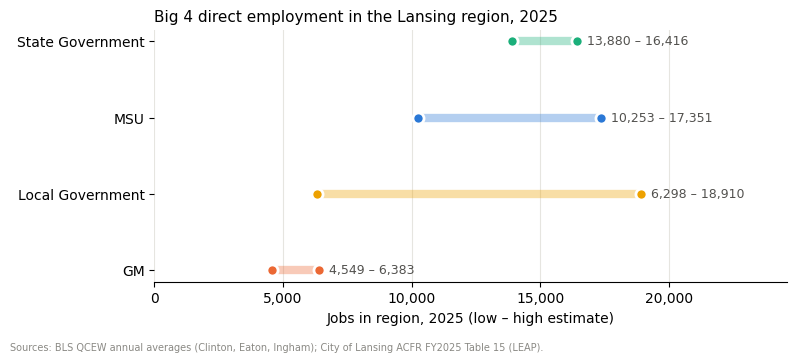

In [6]:
ax.set_yticks(range(len(order)))
ax.set_yticklabels(order)
ax.set_xlabel(f"Jobs in region, {YEAR} (low – high estimate)")
ax.set_xlim(0, fig_data["high"].max() * 1.3)                      # room for the value labels
ax.xaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")             # 10,000 instead of 10000
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.grid(axis="x", color="#e6e5e0", lw=0.8)
ax.set_axisbelow(True)
ax.set_title(f"Big 4 direct employment in the Lansing region, {YEAR}", loc="left", fontsize=11)
fig.text(0.01, 0.01,
         "Sources: BLS QCEW annual averages (Clinton, Eaton, Ingham); City of Lansing ACFR FY2025 Table 15 (LEAP).",
         fontsize=7, color="#8a8984")
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig

## Step 9 — Export the figure and its data, then check the result

In [7]:
fig.savefig(FIG_FILE, dpi=200, bbox_inches="tight", facecolor="white")
fig_data.to_csv(DATA_OUT_FILE)

print("Saved:", FIG_FILE.relative_to(REPO_ROOT), f"({FIG_FILE.stat().st_size / 1024:.0f} KB)")
print("Saved:", DATA_OUT_FILE.relative_to(REPO_ROOT))

# Values in the published version of this figure (2025 data). A reviewer can compare
# their run against these. After an annual data refresh, differences are expected.
EXPECTED_2025 = {"MSU": (10253, 17351), "GM": (4549, 6383),
                 "State Government": (13880, 16416), "Local Government": (6298, 18910)}
if YEAR == 2025:
    check = pd.DataFrame(EXPECTED_2025, index=["expected_low", "expected_high"]).T
    check["your_low"] = fig_data["low"].round()
    check["your_high"] = fig_data["high"].round()
    check["match"] = (check["expected_low"] == check["your_low"]) & (check["expected_high"] == check["your_high"])
    print("\nAll values match the published figure." if check["match"].all()
          else "\nSome values differ from the published figure - see table.")
    display(check)

Saved: figures/fig01_big4_employment_range.png (84 KB)
Saved: figures/fig01_big4_employment_range_data.csv

All values match the published figure.


,expected_low,expected_high,your_low,your_high,match
MSU,10253,17351,10253.0,17351.0,True
GM,4549,6383,4549.0,6383.0,True
State Government,13880,16416,13880.0,16416.0,True
Local Government,6298,18910,6298.0,18910.0,True


## Notes for future updates

- **New year of data.** Re-download QCEW for the new year (Step 3), add it to `Data_Files/qcew_2019_2025_a_focus.csv` (or point `QCEW_FILE` at the new file), and set `YEAR` in Step 4. The LEAP headcounts exist only for the years printed in the ACFR (currently 2025 and 2016), so the low ends for MSU, GM, and State Government need the matching ACFR table.
- **If a new cell is suppressed**, the check in Step 6 stops the notebook with a message instead of drawing a wrong figure.
- **Analysis context.** The full footprint analysis (shares of regional jobs, relative pay, trends, robustness checks) is in `Individual_TeamMember_files/wangz153/01_footprint.ipynb`. This notebook reproduces only Figure 1, using the same definitions.